# Trabajo Práctico II – Desarrollo de Sistemas de Inteligencia Artificial

- **Institución:** Instituto Nuevos Aires — Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial
- **Profesor:** MSc. Ángel Daniel Fuentes S.
- **Alumno:** Ezequiel Quiroga
- **Problema:** Predicción de abandono de clientes (*Customer Churn*) en una empresa de telecomunicaciones
- **Algoritmo elegido:** Opción B — Árbol de Decisión (`DecisionTreeClassifier`)
- **Fuente de datos:** *Telco Customer Churn* (`WA_Fn-UseC_-Telco-Customer-Churn.csv`) en Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## 1. Importación de librerías

Importamos las librerías necesarias para cargar tablas (`pandas`), generar gráficos simples (`matplotlib.pyplot`), dividir los datos (`train_test_split`), construir el Árbol de Decisión (`DecisionTreeClassifier`) y medir su desempeño (`accuracy_score`, `confusion_matrix` y `ConfusionMatrixDisplay`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Librerías importadas correctamente")

Librerías importadas correctamente


## 2. Carga del dataset

Cargamos el archivo CSV descargado desde Kaggle (`WA_Fn-UseC_-Telco-Customer-Churn.csv`), donde cada fila corresponde a un cliente y la columna `Churn` indica si abandonó (`Yes`) o permaneció en la compañía (`No`).

In [2]:
datos = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset cargado correctamente")

Dataset cargado correctamente


## 3. Exploración de los datos

Mostramos los primeros cinco registros, la cantidad total de filas y columnas, los tipos de datos, los valores nulos detectados inicialmente y cuántos clientes abandonaron frente a los que permanecieron.

In [3]:
display(datos.head())
print("Cantidad de filas y columnas:", datos.shape)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Cantidad de filas y columnas: (7043, 21)


In [4]:
datos.info()
print("\nValores nulos iniciales por columna:")
print(datos.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Distribución de clientes según abandono (Churn):
Churn
No     5174
Yes    1869
Name: count, dtype: int64


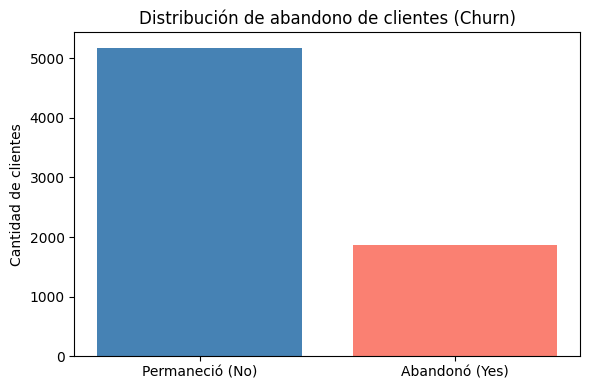

In [5]:
conteo_abandono = datos["Churn"].value_counts()
print("Distribución de clientes según abandono (Churn):")
print(conteo_abandono)

plt.figure(figsize=(6, 4))
plt.bar(["Permaneció (No)", "Abandonó (Yes)"], conteo_abandono.values, color=["steelblue", "salmon"])
plt.title("Distribución de abandono de clientes (Churn)")
plt.ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

**Observaciones iniciales de la exploración:**
- El conjunto de datos tiene **7.043 filas (clientes)** y **21 columnas** con información demográfica, servicios contratados, tipo de contrato, forma de pago y facturación.
- Existe un desequilibrio de clases: **5.174 clientes permanecieron (`No`, 73,46 %)** y **1.869 abandonaron (`Yes`, 26,54 %)**.
- Aunque `isnull().sum()` no muestra nulos al inicio, la columna `TotalCharges` aparece como tipo texto (`str`) en lugar de numérico, lo que indica presencia de caracteres no numéricos o espacios vacíos que debemos tratar en la preparación.

## 4. Preparación de las variables

Seleccionamos 11 variables comerciales y demográficas recomendadas en la consigna (`tenure`, `MonthlyCharges`, `TotalCharges`, `Contract`, `InternetService`, `TechSupport`, `OnlineSecurity`, `PaymentMethod`, `SeniorCitizen`, `Partner` y `Dependents`), excluyendo `customerID` porque es solo un identificador único y no ayuda a generalizar patrones.

Pasos aplicados:
1. Convertimos `TotalCharges` a formato numérico para detectar espacios vacíos como valores faltantes (`NaN`).
2. Como los valores vacíos corresponden a clientes nuevos con antigüedad `0`, los reemplazamos con `0`.
3. Definimos `variables_entrada` (las variables predictoras) convirtiendo las categorías de texto en columnas numéricas binarias (`0`/`1`) mediante `pd.get_dummies(..., drop_first=True)`, y definimos `variable_objetivo` (`Churn`: `No -> 0`, `Yes -> 1`).
4. No aplicamos `StandardScaler` porque los Árboles de Decisión dividen los datos mediante umbrales y no dependen de la escala numérica.

In [6]:
columnas_elegidas = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Contract",
    "InternetService",
    "TechSupport",
    "OnlineSecurity",
    "PaymentMethod",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

datos_preparados = datos[columnas_elegidas + ["Churn"]].copy()
datos_preparados["TotalCharges"] = pd.to_numeric(datos_preparados["TotalCharges"], errors="coerce")

print("Valores faltantes tras convertir TotalCharges a número:")
print(datos_preparados.isnull().sum())

datos_preparados["TotalCharges"] = datos_preparados["TotalCharges"].fillna(0)
print("\nTotal de valores faltantes después del tratamiento:", datos_preparados.isnull().sum().sum())

variables_entrada = pd.get_dummies(datos_preparados[columnas_elegidas], drop_first=True)
variable_objetivo = datos_preparados["Churn"].map({"No": 0, "Yes": 1})

print("Tamaño de variables_entrada:", variables_entrada.shape)
print("Tamaño de variable_objetivo:", variable_objetivo.shape)

Valores faltantes tras convertir TotalCharges a número:
tenure              0
MonthlyCharges      0
TotalCharges       11
Contract            0
InternetService     0
TechSupport         0
OnlineSecurity      0
PaymentMethod       0
SeniorCitizen       0
Partner             0
Dependents          0
Churn               0
dtype: int64

Total de valores faltantes después del tratamiento: 0
Tamaño de variables_entrada: (7043, 17)
Tamaño de variable_objetivo: (7043,)


## 5. Separación de entrenamiento y prueba

Dividimos los datos en **80 % para entrenamiento** y **20 % para prueba**, usando `stratify=variable_objetivo` para conservar la misma proporción de abandonos en ambos subconjuntos y `random_state=42` para que el experimento sea reproducible.

In [7]:
entrada_entrenamiento, entrada_prueba, objetivo_entrenamiento, objetivo_prueba = train_test_split(
    variables_entrada,
    variable_objetivo,
    test_size=0.2,
    stratify=variable_objetivo,
    random_state=42
)

print("Registros para entrenamiento:", len(entrada_entrenamiento))
print("Registros para prueba:", len(entrada_prueba))

Registros para entrenamiento: 5634
Registros para prueba: 1409


## 6. Construcción del modelo

Creamos el clasificador `DecisionTreeClassifier` con los siguientes parámetros principales:
- `criterion="gini"`: criterio que mide qué tan puras quedan las agrupaciones tras cada regla de división.
- `max_depth=4`: limita la profundidad máxima del árbol a 4 niveles para evitar que memorice los datos de entrenamiento y generalice mejor en clientes nuevos.
- `random_state=42`: fija la semilla aleatoria para obtener siempre el mismo resultado.

In [8]:
modelo = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

print("Modelo creado correctamente")

Modelo creado correctamente


## 7. Entrenamiento

Entrenamos el Árbol de Decisión con el 80 % de los datos mediante `.fit()`.

In [9]:
modelo.fit(entrada_entrenamiento, objetivo_entrenamiento)
print("Modelo entrenado correctamente")

Modelo entrenado correctamente


## 8. Predicciones

Generamos las predicciones sobre el 20 % de prueba con `.predict()` y mostramos una tabla comparando tres clientes reales del conjunto de prueba (un caso de permanencia acertado, un caso de abandono acertado y un caso donde el modelo se equivocó).

In [10]:
predicciones = modelo.predict(entrada_prueba)
print("Primeras 10 predicciones:", predicciones[:10])
print("Primeros 10 valores reales:", objetivo_prueba.values[:10])

indices_ejemplo = []
for clase_esperada, prediccion_esperada in [(0, 0), (1, 1), (1, 0)]:
    coincidencias = [
        indice
        for indice, (real, predicho) in enumerate(zip(objetivo_prueba.values, predicciones))
        if real == clase_esperada and predicho == prediccion_esperada
    ]
    if coincidencias:
        indices_ejemplo.append(coincidencias[0])

filas_ejemplo = []
for posicion in indices_ejemplo:
    identificador_fila = entrada_prueba.index[posicion]
    clase_real = "Yes (Abandonó)" if objetivo_prueba.iloc[posicion] == 1 else "No (Permaneció)"
    clase_predicha = "Yes (Abandonó)" if predicciones[posicion] == 1 else "No (Permaneció)"
    resultado = "Correcta" if objetivo_prueba.iloc[posicion] == predicciones[posicion] else "Incorrecta"
    filas_ejemplo.append(
        {
            "Indice_registro": identificador_fila,
            "Antiguedad_meses": datos_preparados.loc[identificador_fila, "tenure"],
            "Cargo_mensual": datos_preparados.loc[identificador_fila, "MonthlyCharges"],
            "Contrato": datos_preparados.loc[identificador_fila, "Contract"],
            "Clase_real": clase_real,
            "Clase_predicha": clase_predicha,
            "Prediccion": resultado,
        }
    )

tabla_ejemplos = pd.DataFrame(filas_ejemplo)
display(tabla_ejemplos)

Primeras 10 predicciones: [0 1 0 0 0 0 0 0 0 0]
Primeros 10 valores reales: [0 0 0 0 0 0 0 0 0 1]


,Indice_registro,Antiguedad_meses,Cargo_mensual,Contrato,Clase_real,Clase_predicha,Prediccion
0,437,72,114.05,Two year,No (Permaneció),No (Permaneció),Correcta
1,3524,11,84.80,Month-to-month,Yes (Abandonó),Yes (Abandonó),Correcta
2,1639,17,45.05,Month-to-month,Yes (Abandonó),No (Permaneció),Incorrecta


## 9. Evaluación

Calculamos la exactitud (`accuracy_score`) y mostramos la matriz de confusión en formato tabla y gráfico para interpretar los aciertos y errores sobre los 1.409 clientes del conjunto de prueba.

Exactitud (Accuracy): 79.56%


,Predicho: No (0),Predicho: Yes (1)
Real: No (0),929,106
Real: Yes (1),182,192


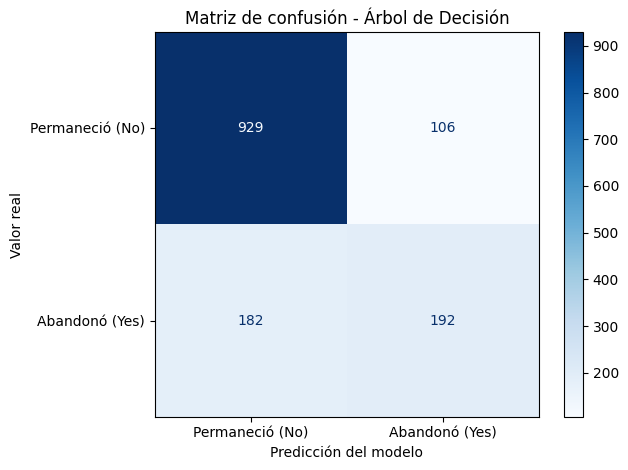

In [11]:
exactitud = accuracy_score(objetivo_prueba, predicciones)
print(f"Exactitud (Accuracy): {round(exactitud * 100, 2)}%")

matriz_confusion = confusion_matrix(objetivo_prueba, predicciones)
tabla_metricas = pd.DataFrame(
    matriz_confusion,
    index=["Real: No (0)", "Real: Yes (1)"],
    columns=["Predicho: No (0)", "Predicho: Yes (1)"]
)
display(tabla_metricas)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=["Permaneció (No)", "Abandonó (Yes)"]
)
visualizacion.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Árbol de Decisión")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

**Interpretación de resultados:**
- El modelo alcanza una exactitud de **79,56 %** (acierta 1.121 de los 1.409 casos de prueba).
- Identifica correctamente a **929 clientes que permanecieron** y a **192 clientes que abandonaron**.
- Sin embargo, clasifica erróneamente como permanencia a **182 clientes que en realidad abandonaron** (falsos negativos) y marca como posible abandono a **106 clientes que permanecieron** (falsos positivos).

## 10. Conclusiones

1. **¿Qué problema resolviste?**
   Se desarrolló un sistema de clasificación binaria supervisada para predecir si un cliente de telecomunicaciones abandonará la compañía (`Churn = Yes`) o permanecerá en ella (`Churn = No`).

2. **¿Qué algoritmo seleccionaste y por qué?**
   Se eligió **Árbol de Decisión (`DecisionTreeClassifier`)** porque genera reglas fáciles de interpretar en el ámbito comercial (por ejemplo, según antigüedad o tipo de contrato) y no requiere escalar las variables numéricas.

3. **¿Qué variables utilizaste y por qué?**
   Se seleccionaron 11 características clave del historial del cliente (`tenure`, `MonthlyCharges`, `TotalCharges`, `Contract`, `InternetService`, `TechSupport`, `OnlineSecurity`, `PaymentMethod`, `SeniorCitizen`, `Partner` y `Dependents`) porque reflejan su vínculo contractual, gasto y servicios activos, y se excluyó `customerID` por ser únicamente un identificador sin capacidad de generalización.

4. **¿Qué resultados obtuviste?**
   Con una profundidad máxima de 4 niveles y una división 80/20 estratificada, el modelo obtuvo una **exactitud de 79,56 %** en el conjunto de prueba (1.121 aciertos sobre 1.409 clientes).

5. **¿Qué errores cometió el modelo?**
   Su error más frecuente fueron los **falsos negativos** (182 clientes que abandonaron pero fueron predichos como que permanecían), además de 106 falsos positivos.

6. **¿Qué limitaciones identificaste?**
   El dataset presenta un **desequilibrio importante de clases** (73,46 % `No` frente a 26,54 % `Yes`), por lo que el árbol aprende con mayor facilidad a detectar clientes que se quedan que a captar todos los abandonos. Además, el modelo no incluye factores externos como promociones de la competencia o atención al cliente.